# Variational Autoencoder (VAE) – MNIST

**Student:** Harshad Santosh Dhokare  
**PRN:** 202401110024  
**Course:** Generative AI (2311312T)

**Research paper:** Kingma, D. P., & Welling, M. (2013). *Auto-Encoding Variational Bayes*. https://arxiv.org/abs/1312.6114

**Aim:** Train a VAE to reconstruct and generate handwritten digits.

## 1. Import libraries and select device

In [1]:
import os
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


## 2. Download and prepare MNIST

In [2]:
# Download the MNIST archive if it is not already present.
os.makedirs("data", exist_ok=True)
DATA_PATH = "data/mnist.npz"
DATA_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

if not os.path.exists(DATA_PATH) or os.path.getsize(DATA_PATH) == 0:
    print("Downloading MNIST dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with np.load(DATA_PATH) as data:
    x_train = data["x_train"]
    x_test = data["x_test"]

# Scale pixel values to [0, 1] and flatten each 28x28 image.
train_images = torch.from_numpy(x_train.copy()).float().div(255.0).view(-1, 784)
test_images = torch.from_numpy(x_test.copy()).float().div(255.0).view(-1, 784)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(train_images), batch_size=BATCH_SIZE, shuffle=True)
print("Training images:", len(train_images))
print("Test images:", len(test_images))

Training images: 60000
Test images: 10000


## 3. Define the VAE model

In [3]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):
        super().__init__()
        self.encoder = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Linear(latent_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, input_dim)

    def encode(self, x):
        hidden = F.relu(self.encoder(x))
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def decode(self, z):
        hidden = F.relu(self.decoder(z))
        return torch.sigmoid(self.output_layer(hidden))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

LATENT_DIM = 20
model = VAE(latent_dim=LATENT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)

VAE(
  (encoder): Linear(in_features=784, out_features=400, bias=True)
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (decoder): Linear(in_features=20, out_features=400, bias=True)
  (output_layer): Linear(in_features=400, out_features=784, bias=True)
)


## 4. Define the loss function

In [4]:
def vae_loss(reconstructed, original, mu, logvar):
    reconstruction_loss = F.binary_cross_entropy(
        reconstructed, original, reduction="sum"
    )
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )
    total_loss = reconstruction_loss + kl_loss
    return total_loss, reconstruction_loss, kl_loss

## 5. Train the model

In [5]:
EPOCHS = 10
loss_history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for (images,) in train_loader:
        images = images.to(DEVICE)
        optimizer.zero_grad()
        reconstructed, mu, logvar = model(images)
        loss, _, _ = vae_loss(reconstructed, images, mu, logvar)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    average_loss = total_loss / len(train_images)
    loss_history.append(average_loss)
    print(f"Epoch {epoch + 1}/{EPOCHS} - Loss per image: {average_loss:.4f}")

Epoch 1/10 - Loss per image: 165.6817
Epoch 2/10 - Loss per image: 121.8054
Epoch 3/10 - Loss per image: 114.8626
Epoch 4/10 - Loss per image: 111.9616
Epoch 5/10 - Loss per image: 110.1205
Epoch 6/10 - Loss per image: 108.9645
Epoch 7/10 - Loss per image: 108.1110
Epoch 8/10 - Loss per image: 107.4610
Epoch 9/10 - Loss per image: 106.8871
Epoch 10/10 - Loss per image: 106.4715


## 6. Plot training loss

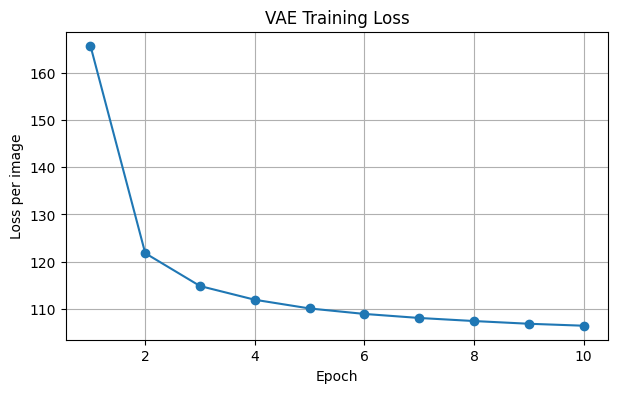

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss per image")
plt.title("VAE Training Loss")
plt.grid(True)
plt.show()

## 7. Reconstruct test images

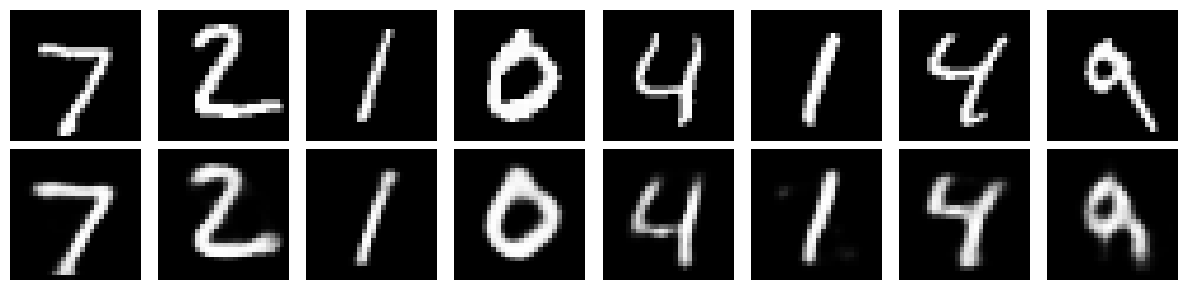

In [7]:
model.eval()
images = test_images[:8].to(DEVICE)

with torch.no_grad():
    reconstructed, _, _ = model(images)

original = images.cpu().view(-1, 1, 28, 28)
reconstructed = reconstructed.cpu().view(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(original[i, 0], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()
plt.show()

## 8. Generate new handwritten digits

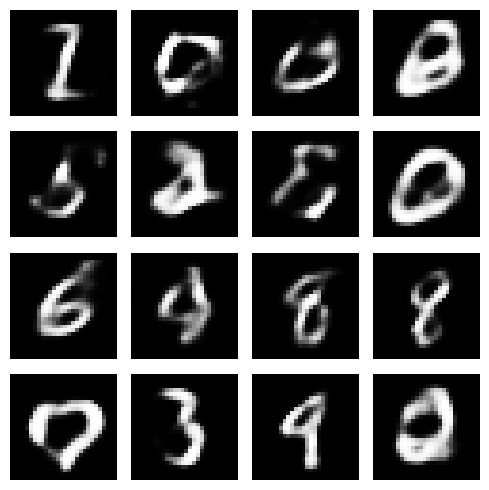

In [8]:
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=DEVICE)
    generated = model.decode(z).cpu().view(-1, 1, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i, 0], cmap="gray")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Save the trained model

In [9]:
torch.save(model.state_dict(), "mnist_vae.pth")
print("Model saved as mnist_vae.pth")

Model saved as mnist_vae.pth
